In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/andrihjonior/cert-insider-threat-dataset-r4-2/answers/readme.txt
/kaggle/input/datasets/andrihjonior/cert-insider-threat-dataset-r4-2/answers/scenarios.txt
/kaggle/input/datasets/andrihjonior/cert-insider-threat-dataset-r4-2/answers/license.txt
/kaggle/input/datasets/andrihjonior/cert-insider-threat-dataset-r4-2/answers/insiders.csv
/kaggle/input/datasets/andrihjonior/cert-insider-threat-dataset-r4-2/answers/r4.2-2/r4.2-2-MOS0047.csv
/kaggle/input/datasets/andrihjonior/cert-insider-threat-dataset-r4-2/answers/r4.2-2/r4.2-2-IKR0401.csv
/kaggle/input/datasets/andrihjonior/cert-insider-threat-dataset-r4-2/answers/r4.2-2/r4.2-2-DRR0162.csv
/kaggle/input/datasets/andrihjonior/cert-insider-threat-dataset-r4-2/answers/r4.2-2/r4.2-2-CQW0652.csv
/kaggle/input/datasets/andrihjonior/cert-insider-threat-dataset-r4-2/answers/r4.2-2/r4.2-2-PSF0133.csv
/kaggle/input/datasets/andrihjonior/cert-insider-threat-dataset-r4-2/answers/r4.2-2/r4.2-2-KRL0501.csv
/kaggle/input/datasets/a

In [2]:
# ============================================================
# CERT 4.2 - NOTEBOOK 1 MASTER BOOTSTRAP
# ============================================================

import os
import gc
import numpy as np
import pandas as pd

from pathlib import Path

pd.set_option("display.max_columns", None)

# ============================================================
# PATHS
# ============================================================

CERT_PATH = "/kaggle/input/datasets/utkarshkanwat/certr42/r4.2"
ANSWER_PATH = "/kaggle/input/datasets/andrihjonior/cert-insider-threat-dataset-r4-2"
LDAP_PATH = f"{ANSWER_PATH}/r4.2/LDAP"

# ============================================================
# LOAD RAW FILES
# ============================================================

print("Loading Raw Files...")

logon_df = pd.read_csv(
    f"{CERT_PATH}/logon.csv"
)

device_df = pd.read_csv(
    f"{CERT_PATH}/device.csv"
)

email_df = pd.read_csv(
    f"{CERT_PATH}/email.csv"
)

file_df = pd.read_csv(
    f"{CERT_PATH}/file.csv"
)

psych_df = pd.read_csv(
    f"{CERT_PATH}/psychometric.csv"
)

print("Raw Files Loaded")

# ============================================================
# DATETIME CONVERSION
# ============================================================

print("Converting Dates...")

logon_df["date"] = pd.to_datetime(
    logon_df["date"]
)

device_df["date"] = pd.to_datetime(
    device_df["date"]
)

email_df["date"] = pd.to_datetime(
    email_df["date"]
)

file_df["date"] = pd.to_datetime(
    file_df["date"]
)

# ============================================================
# LDAP MASTER
# ============================================================

if os.path.exists("ldap_master.parquet"):

    print("Loading ldap_master.parquet")

    ldap_master = pd.read_parquet(
        "ldap_master.parquet"
    )

else:

    print("Building LDAP Master...")

    ldap_frames = []

    ldap_files = sorted(
        [
            f
            for f in os.listdir(LDAP_PATH)
            if f.endswith(".csv")
        ]
    )

    for file in ldap_files:

        temp = pd.read_csv(
            f"{LDAP_PATH}/{file}"
        )

        temp["snapshot_file"] = file

        ldap_frames.append(temp)

    ldap_df = pd.concat(
        ldap_frames,
        ignore_index=True
    )

    ldap_df["snapshot_date"] = pd.to_datetime(
        ldap_df["snapshot_file"]
        .str.replace(".csv", ""),
        format="%Y-%m"
    )

    ldap_master = (
        ldap_df
        .sort_values("snapshot_date")
        .groupby("user_id")
        .tail(1)
        .reset_index(drop=True)
    )

    ldap_master.to_parquet(
        "ldap_master.parquet",
        index=False
    )

    del ldap_df
    gc.collect()

# ============================================================
# LABELS DF
# ============================================================

if os.path.exists("labels_df.parquet"):

    print("Loading labels_df.parquet")

    labels_df = pd.read_parquet(
        "labels_df.parquet"
    )

else:

    print("Building labels_df...")

    insiders_df = pd.read_csv(
        f"{ANSWER_PATH}/answers/insiders.csv"
    )

    insiders_df["start"] = pd.to_datetime(
        insiders_df["start"],
        errors="coerce",
        format="mixed"
    )

    insiders_df["end"] = pd.to_datetime(
        insiders_df["end"],
        errors="coerce",
        format="mixed"
    )

    labels_df = (
        insiders_df[
            insiders_df["dataset"] == 4.2
        ]
        .copy()
    )

    labels_df = labels_df[
        [
            "user",
            "scenario",
            "details",
            "start",
            "end"
        ]
    ]

    labels_df.rename(
        columns={
            "start": "attack_start",
            "end": "attack_end"
        },
        inplace=True
    )

    labels_df.to_parquet(
        "labels_df.parquet",
        index=False
    )

# ============================================================
# ATTACK OBSERVABLES
# ============================================================

if os.path.exists(
    "attack_observables.parquet"
):

    print(
        "Loading attack_observables.parquet"
    )

    attack_observables = pd.read_parquet(
        "attack_observables.parquet"
    )

else:

    print(
        "Building attack_observables..."
    )

    answer_files = []

    for root, dirs, files in os.walk(
        f"{ANSWER_PATH}/answers"
    ):

        for file in files:

            if (
                file.endswith(".csv")
                and file != "insiders.csv"
            ):

                answer_files.append(
                    os.path.join(root, file)
                )

    observable_frames = []

    for file in answer_files:

        try:

            temp = pd.read_csv(
                file,
                header=None,
                on_bad_lines="skip"
            )

            temp["source_file"] = (
                os.path.basename(file)
            )

            observable_frames.append(
                temp
            )

        except:

            pass

    attack_observables = pd.concat(
        observable_frames,
        ignore_index=True
    )

    attack_observables.columns = [
        f"col_{i}"
        for i in range(
            attack_observables.shape[1]
        )
    ]

    attack_observables.rename(
        columns={
            "col_0":"event_type",
            "col_1":"event_id",
            "col_2":"timestamp",
            "col_3":"user",
            "col_4":"pc"
        },
        inplace=True
    )

    attack_observables["timestamp"] = (
        pd.to_datetime(
            attack_observables["timestamp"],
            errors="coerce"
        )
    )

    attack_observables.to_parquet(
        "attack_observables.parquet",
        index=False
    )

# ============================================================
# TIMELINE V1
# ============================================================

if os.path.exists(
    "timeline_v1.parquet"
):

    print("Loading timeline_v1.parquet")

    timeline_df = pd.read_parquet(
        "timeline_v1.parquet"
    )

else:

    print("Building timeline_v1...")

    timeline_logon = pd.DataFrame({

        "timestamp":
            logon_df["date"],

        "user":
            logon_df["user"],

        "pc":
            logon_df["pc"],

        "event_type":
            logon_df["activity"],

        "event_id":
            logon_df["id"],

        "payload":
            None
    })

    timeline_device = pd.DataFrame({

        "timestamp":
            device_df["date"],

        "user":
            device_df["user"],

        "pc":
            device_df["pc"],

        "event_type":
            device_df["activity"],

        "event_id":
            device_df["id"],

        "payload":
            None
    })

    timeline_email = pd.DataFrame({

        "timestamp":
            email_df["date"],

        "user":
            email_df["user"],

        "pc":
            email_df["pc"],

        "event_type":
            "EMAIL",

        "event_id":
            email_df["id"],

        "payload":
            email_df["to"]
    })

    timeline_file = pd.DataFrame({

        "timestamp":
            file_df["date"],

        "user":
            file_df["user"],

        "pc":
            file_df["pc"],

        "event_type":
            "FILE_COPY",

        "event_id":
            file_df["id"],

        "payload":
            file_df["filename"]
    })

    timeline_df = pd.concat(
        [
            timeline_logon,
            timeline_device,
            timeline_email,
            timeline_file
        ],
        ignore_index=True
    )

    timeline_df.sort_values(
        "timestamp",
        inplace=True
    )

    timeline_df.reset_index(
        drop=True,
        inplace=True
    )

    timeline_df.to_parquet(
        "timeline_v1.parquet",
        index=False
    )

# ============================================================
# SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("CERT 4.2 BOOTSTRAP COMPLETE")
print("=" * 70)

print(
    f"\nLDAP MASTER: "
    f"{ldap_master.shape}"
)

print(
    f"\nLABELS DF: "
    f"{labels_df.shape}"
)

print(
    f"\nATTACK OBSERVABLES: "
    f"{attack_observables.shape}"
)

print(
    f"\nTIMELINE V1: "
    f"{timeline_df.shape}"
)


Loading Raw Files...
Raw Files Loaded
Converting Dates...
Building LDAP Master...
Building labels_df...
Building attack_observables...
Building timeline_v1...


CERT 4.2 BOOTSTRAP COMPLETE

LDAP MASTER: (1000, 11)

LABELS DF: (70, 5)

ATTACK OBSERVABLES: (6834, 13)

TIMELINE V1: (4335799, 6)


In [3]:
# ============================================================
# FEATURE ENGINEERING BOOTSTRAP
# Produces:
# daily_features
# ============================================================

import numpy as np
import pandas as pd
from urllib.parse import urlparse

print("Starting Feature Engineering...")

# ============================================================
# TIME FEATURES
# ============================================================

timeline_df["date"] = timeline_df["timestamp"].dt.floor("D")
timeline_df["hour"] = timeline_df["timestamp"].dt.hour
timeline_df["dayofweek"] = timeline_df["timestamp"].dt.dayofweek

timeline_df["is_weekend"] = (
    timeline_df["dayofweek"] >= 5
).astype(int)

timeline_df["after_hours"] = (
    (timeline_df["hour"] < 7)
    |
    (timeline_df["hour"] > 18)
).astype(int)

# ============================================================
# USER DAY SKELETON
# ============================================================

daily_features = (
    timeline_df[
        ["user","date"]
    ]
    .drop_duplicates()
    .sort_values(
        ["user","date"]
    )
    .reset_index(drop=True)
)

# ============================================================
# LOGON FEATURES
# ============================================================

logon_features = (
    timeline_df[
        timeline_df["event_type"]
        .isin(["Logon","Logoff"])
    ]
    .groupby(["user","date"])
    .agg(
        total_logons=("event_type",
                      lambda x:(x=="Logon").sum()),
        total_logoffs=("event_type",
                       lambda x:(x=="Logoff").sum()),
        unique_pcs=("pc","nunique"),
        after_hours_logons=("after_hours","sum"),
        weekend_logons=("is_weekend","sum")
    )
    .reset_index()
)

# ============================================================
# DEVICE FEATURES
# ============================================================

device_features = (
    timeline_df[
        timeline_df["event_type"]
        .isin(["Connect","Disconnect"])
    ]
    .groupby(["user","date"])
    .agg(
        usb_connects=("event_type",
                      lambda x:(x=="Connect").sum()),
        usb_disconnects=("event_type",
                         lambda x:(x=="Disconnect").sum()),
        usb_after_hours=("after_hours","sum"),
        weekend_usb=("is_weekend","sum")
    )
    .reset_index()
)

# ============================================================
# EMAIL FEATURES
# ============================================================

email_rows = timeline_df[
    timeline_df["event_type"]=="EMAIL"
].copy()

email_rows["recipient_count"] = (
    email_rows["payload"]
    .fillna("")
    .astype(str)
    .str.count(";")
    + 1
)

email_features = (
    email_rows
    .groupby(["user","date"])
    .agg(
        emails_sent=("event_id","count"),
        unique_recipients=("payload","nunique"),
        avg_recipients=("recipient_count","mean"),
        max_recipients=("recipient_count","max")
    )
    .reset_index()
)

# ============================================================
# FILE FEATURES
# ============================================================

file_rows = timeline_df[
    timeline_df["event_type"]=="FILE_COPY"
].copy()

file_rows["extension"] = (
    file_rows["payload"]
    .astype(str)
    .str.extract(r"\.([A-Za-z0-9]+)$")
)

file_features = (
    file_rows
    .groupby(["user","date"])
    .agg(
        files_copied=("event_id","count"),
        unique_extensions=("extension","nunique")
    )
    .reset_index()
)

# ============================================================
# MERGE BASE FEATURES
# ============================================================

daily_features = (
    daily_features
    .merge(logon_features,on=["user","date"],how="left")
    .merge(device_features,on=["user","date"],how="left")
    .merge(email_features,on=["user","date"],how="left")
    .merge(file_features,on=["user","date"],how="left")
)

daily_features.fillna(0,inplace=True)

# ============================================================
# LDAP
# ============================================================

ldap_features = ldap_master[
    [
        "user_id",
        "role",
        "department",
        "team",
        "functional_unit",
        "business_unit"
    ]
].copy()

ldap_features.rename(
    columns={"user_id":"user"},
    inplace=True
)

daily_features = (
    daily_features
    .merge(
        ldap_features,
        on="user",
        how="left"
    )
)

# ============================================================
# PSYCHOMETRIC
# ============================================================

psych_features = psych_df.copy()

psych_features.rename(
    columns={
        "user_id":"user"
    },
    inplace=True
)

daily_features = (
    daily_features
    .merge(
        psych_features[
            ["user","O","C","E","A","N"]
        ],
        on="user",
        how="left"
    )
)

# ============================================================
# LABELS
# ============================================================

daily_features["label"] = 0

for _, attack in labels_df.iterrows():

    mask = (
        (daily_features["user"] == attack["user"])
        &
        (
            daily_features["date"]
            >= attack["attack_start"].floor("D")
        )
        &
        (
            daily_features["date"]
            <= attack["attack_end"].floor("D")
        )
    )

    daily_features.loc[
        mask,
        "label"
    ] = 1

# ============================================================
# BEHAVIORAL DEVIATIONS
# ============================================================

daily_features = (
    daily_features
    .sort_values(
        ["user","date"]
    )
)

behavior_cols = [
    "total_logons",
    "after_hours_logons",
    "usb_connects",
    "usb_after_hours",
    "emails_sent",
    "unique_recipients",
    "files_copied"
]

for col in behavior_cols:

    daily_features[
        f"{col}_30d_avg"
    ] = (
        daily_features
        .groupby("user")[col]
        .transform(
            lambda x:
            x.shift(1)
             .rolling(
                 30,
                 min_periods=3
             )
             .mean()
        )
    )

    daily_features[
        f"{col}_30d_std"
    ] = (
        daily_features
        .groupby("user")[col]
        .transform(
            lambda x:
            x.shift(1)
             .rolling(
                 30,
                 min_periods=3
             )
             .std()
        )
    )

for col in behavior_cols:

    avg_col = f"{col}_30d_avg"
    std_col = f"{col}_30d_std"

    daily_features[
        f"{col}_deviation"
    ] = np.where(

        daily_features[std_col] < 0.5,

        daily_features[col]
        -
        daily_features[avg_col],

        (
            daily_features[col]
            -
            daily_features[avg_col]
        )
        /
        daily_features[std_col]
    )

daily_features.fillna(0,inplace=True)

print("Feature Store Created")
print(daily_features.shape)

Starting Feature Engineering...
Feature Store Created
(330452, 49)


In [4]:
# ============================================================
# BOOTSTRAP C
# SOCIAL + HTTP + TOPIC FEATURES
# ============================================================

import numpy as np
import pandas as pd
from urllib.parse import urlparse

print("=" * 60)
print("BOOTSTRAP C STARTING")
print("=" * 60)

# ============================================================
# SOCIAL GRAPH FEATURES
# ============================================================

print("Building Social Features...")

email_social = email_df.copy()

email_social["date"] = pd.to_datetime(
    email_social["date"]
).dt.floor("D")

email_social["to"] = (
    email_social["to"]
    .fillna("")
    .astype(str)
)

email_social["cc"] = (
    email_social["cc"]
    .fillna("")
    .astype(str)
)

email_social["bcc"] = (
    email_social["bcc"]
    .fillna("")
    .astype(str)
)

email_social["to_count"] = (
    email_social["to"]
    .str.count(";")
    + 1
)

email_social["cc_count"] = np.where(
    email_social["cc"] == "",
    0,
    email_social["cc"].str.count(";") + 1
)

email_social["bcc_count"] = np.where(
    email_social["bcc"] == "",
    0,
    email_social["bcc"].str.count(";") + 1
)

def count_external_recipients(recipient_string):

    if recipient_string == "":
        return 0

    recipients = recipient_string.split(";")

    return sum(
        "@dtaa.com" not in r.lower()
        for r in recipients
    )

email_social["external_total"] = (
    email_social["to"].apply(count_external_recipients)
    +
    email_social["cc"].apply(count_external_recipients)
    +
    email_social["bcc"].apply(count_external_recipients)
)

social_features = (
    email_social
    .groupby(
        ["user","date"]
    )
    .agg(
        total_email_size=("size","sum"),
        avg_email_size=("size","mean"),
        total_attachments=("attachments","sum"),
        avg_attachments=("attachments","mean"),
        total_external_contacts=("external_total","sum"),
        avg_to_count=("to_count","mean"),
        avg_cc_count=("cc_count","mean"),
        avg_bcc_count=("bcc_count","mean")
    )
    .reset_index()
)

daily_features = (
    daily_features
    .merge(
        social_features,
        on=["user","date"],
        how="left"
    )
)

daily_features.fillna(0,inplace=True)

daily_features["external_contact_ratio"] = (
    daily_features["total_external_contacts"]
    /
    (
        daily_features["emails_sent"] + 1
    )
)

print("Social Features Done")

# ============================================================
# HTTP FEATURES
# ============================================================

print("Building HTTP Features...")

HTTP_PATH = f"{CERT_PATH}/http.csv"

JOB_DOMAINS = {
    "monster.com",
    "indeed.com",
    "careerbuilder.com",
    "job-hunt.org"
}

def extract_domain(url):

    try:
        return urlparse(
            str(url)
        ).netloc.lower()

    except:
        return "unknown"

http_chunks = []

for i, chunk in enumerate(
    pd.read_csv(
        HTTP_PATH,
        chunksize=500000
    )
):

    print(
        f"HTTP Chunk {i+1}"
    )

    chunk["date"] = pd.to_datetime(
        chunk["date"]
    )

    chunk["day"] = (
        chunk["date"]
        .dt.floor("D")
    )

    chunk["hour"] = (
        chunk["date"]
        .dt.hour
    )

    chunk["domain"] = (
        chunk["url"]
        .astype(str)
        .apply(extract_domain)
    )

    chunk["after_hours"] = (
        (
            chunk["hour"] < 7
        )
        |
        (
            chunk["hour"] > 18
        )
    ).astype(int)

    chunk["job_search"] = (
        chunk["domain"]
        .isin(JOB_DOMAINS)
    ).astype(int)

    agg = (
        chunk
        .groupby(
            ["user","day"]
        )
        .agg(
            http_visits=("id","count"),
            unique_domains=("domain","nunique"),
            after_hours_http=("after_hours","sum"),
            job_search_visits=("job_search","sum")
        )
        .reset_index()
    )

    http_chunks.append(agg)

    del chunk

http_features = pd.concat(
    http_chunks,
    ignore_index=True
)

http_features = (
    http_features
    .groupby(
        ["user","day"]
    )
    .sum()
    .reset_index()
)

http_features.rename(
    columns={
        "day":"date"
    },
    inplace=True
)

print("HTTP Features Done")

# ============================================================
# HTTP DEVIATIONS
# ============================================================

print("Building HTTP Deviations...")

http_features = (
    http_features
    .sort_values(
        ["user","date"]
    )
)

http_cols = [
    "http_visits",
    "unique_domains",
    "job_search_visits"
]

for col in http_cols:

    http_features[
        f"{col}_30d_avg"
    ] = (
        http_features
        .groupby("user")[col]
        .transform(
            lambda x:
            x.shift(1)
             .rolling(
                 30,
                 min_periods=3
             )
             .mean()
        )
    )

    http_features[
        f"{col}_30d_std"
    ] = (
        http_features
        .groupby("user")[col]
        .transform(
            lambda x:
            x.shift(1)
             .rolling(
                 30,
                 min_periods=3
             )
             .std()
        )
    )

for col in http_cols:

    avg_col = f"{col}_30d_avg"
    std_col = f"{col}_30d_std"

    http_features[
        f"{col}_deviation"
    ] = np.where(

        http_features[std_col] < 0.5,

        http_features[col]
        -
        http_features[avg_col],

        (
            http_features[col]
            -
            http_features[avg_col]
        )
        /
        http_features[std_col]
    )

http_features.fillna(
    0,
    inplace=True
)

daily_features = (
    daily_features
    .merge(
        http_features,
        on=["user","date"],
        how="left"
    )
)

daily_features.fillna(
    0,
    inplace=True
)

print("HTTP Deviations Done")

# ============================================================
# TOPIC FEATURES
# ============================================================

print("Building Topic Features...")

topic_chunks = []

for i, chunk in enumerate(
    pd.read_csv(
        HTTP_PATH,
        chunksize=500000,
        usecols=[
            "date",
            "user",
            "content"
        ]
    )
):

    print(
        f"Topic Chunk {i+1}"
    )

    chunk["date"] = pd.to_datetime(
        chunk["date"]
    ).dt.floor("D")

    chunk["topic_count"] = (
        chunk["content"]
        .fillna("")
        .astype(str)
        .str.split()
        .str.len()
    )

    agg = (
        chunk
        .groupby(
            ["user","date"]
        )
        .agg(
            avg_topics_per_page=(
                "topic_count",
                "mean"
            ),
            max_topics_per_page=(
                "topic_count",
                "max"
            )
        )
        .reset_index()
    )

    topic_chunks.append(
        agg
    )

    del chunk

topic_features = pd.concat(
    topic_chunks,
    ignore_index=True
)

topic_features = (
    topic_features
    .groupby(
        ["user","date"]
    )
    .mean()
    .reset_index()
)

topic_features.fillna(
    0,
    inplace=True
)

daily_features = (
    daily_features
    .merge(
        topic_features,
        on=["user","date"],
        how="left"
    )
)

daily_features.fillna(
    0,
    inplace=True
)

print("Topic Features Done")

# ============================================================
# FINAL CLEANUP
# ============================================================

object_cols = (
    daily_features
    .select_dtypes(
        include=["object"]
    )
    .columns
)

for col in object_cols:

    daily_features[col] = (
        daily_features[col]
        .fillna("UNKNOWN")
        .astype(str)
    )

print("=" * 60)
print("BOOTSTRAP C COMPLETE")
print("=" * 60)
print(daily_features.shape)

BOOTSTRAP C STARTING
Building Social Features...
Social Features Done
Building HTTP Features...
HTTP Chunk 1
HTTP Chunk 2
HTTP Chunk 3
HTTP Chunk 4
HTTP Chunk 5
HTTP Chunk 6
HTTP Chunk 7
HTTP Chunk 8
HTTP Chunk 9
HTTP Chunk 10
HTTP Chunk 11
HTTP Chunk 12
HTTP Chunk 13
HTTP Chunk 14
HTTP Chunk 15
HTTP Chunk 16
HTTP Chunk 17
HTTP Chunk 18
HTTP Chunk 19
HTTP Chunk 20
HTTP Chunk 21
HTTP Chunk 22
HTTP Chunk 23
HTTP Chunk 24
HTTP Chunk 25
HTTP Chunk 26
HTTP Chunk 27
HTTP Chunk 28
HTTP Chunk 29
HTTP Chunk 30
HTTP Chunk 31
HTTP Chunk 32
HTTP Chunk 33
HTTP Chunk 34
HTTP Chunk 35
HTTP Chunk 36
HTTP Chunk 37
HTTP Chunk 38
HTTP Chunk 39
HTTP Chunk 40
HTTP Chunk 41
HTTP Chunk 42
HTTP Chunk 43
HTTP Chunk 44
HTTP Chunk 45
HTTP Chunk 46
HTTP Chunk 47
HTTP Chunk 48
HTTP Chunk 49
HTTP Chunk 50
HTTP Chunk 51
HTTP Chunk 52
HTTP Chunk 53
HTTP Chunk 54
HTTP Chunk 55
HTTP Chunk 56
HTTP Chunk 57
HTTP Features Done
Building HTTP Deviations...
HTTP Deviations Done
Building Topic Features...
Topic Chunk 1
Topic 

In [5]:
# ============================================================
# FEATURE PACK D
# EXFILTRATION FEATURES
# ============================================================

daily_features["usb_file_ratio"] = (
    daily_features["files_copied"]
    /
    (
        daily_features["usb_connects"] + 1
    )
)

daily_features["after_hours_file_ratio"] = (
    daily_features["files_copied"]
    /
    (
        daily_features["after_hours_logons"] + 1
    )
)

daily_features["external_email_ratio"] = (
    daily_features["total_external_contacts"]
    /
    (
        daily_features["emails_sent"] + 1
    )
)

print("Exfiltration Features Added")

# ============================================================
# ACTIVITY BURST FEATURES
# ============================================================

daily_features["activity_volume"] = (

      daily_features["emails_sent"]
    + daily_features["files_copied"]
    + daily_features["http_visits"]

)

daily_features["activity_volume_30d_avg"] = (

    daily_features
    .groupby("user")["activity_volume"]
    .transform(

        lambda x:
        x.shift(1)
         .rolling(
             30,
             min_periods=3
         )
         .mean()
    )
)

daily_features["activity_volume_deviation"] = (

    daily_features["activity_volume"]
    -
    daily_features["activity_volume_30d_avg"]

)

print("Activity Features Added")

# ============================================================
# COMPOSITE RISK FEATURES
# ============================================================

daily_features["behavior_risk_score"] = (

      daily_features["usb_connects_deviation"] * 2

    + daily_features["files_copied_deviation"] * 3

    + daily_features["http_visits_deviation"] * 2

    + daily_features["job_search_visits_deviation"] * 2

)

daily_features["after_hours_risk"] = (

      daily_features["after_hours_logons"]

    + daily_features["after_hours_http"]

    + daily_features["usb_after_hours"]

)

print("Risk Features Added")

daily_features.fillna(
    0,
    inplace=True
)

print(daily_features.shape)

Exfiltration Features Added
Activity Features Added
Risk Features Added
(330452, 81)


In [6]:
daily_features.to_parquet(
    "/kaggle/working/daily_features_v5.parquet",
    index=False
)

print("Feature Store Saved")

Feature Store Saved


In [7]:
from sklearn.preprocessing import LabelEncoder

model_df = daily_features.copy()

for col in ["role", "department", "team", "functional_unit"]:

    if col in model_df.columns:

        le = LabelEncoder()

        model_df[col] = le.fit_transform(
            model_df[col].astype(str)
        )

model_df = (
    model_df
    .sort_values("date")
    .reset_index(drop=True)
)

split_idx = int(len(model_df) * 0.8)

train_df = model_df.iloc[:split_idx]
test_df = model_df.iloc[split_idx:]

X_train = train_df.drop(
    columns=["user", "date", "label"]
)

X_test = test_df.drop(
    columns=["user", "date", "label"]
)

y_train = train_df["label"]
y_test = test_df["label"]

print(X_train.shape)
print(X_test.shape)

(264361, 78)
(66091, 78)


In [8]:
from catboost import CatBoostClassifier

cat_e = CatBoostClassifier(
    iterations=500,
    depth=8,
    learning_rate=0.05,
    random_seed=42,
    verbose=False
)

cat_e.fit(
    X_train,
    y_train
)

CatBoostClassifier(depth=8, iterations=500, learning_rate=0.05, random_seed=42, verbose=False)

In [9]:
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    f1_score,
    confusion_matrix
)

pred_probs = (
    cat_e.predict_proba(X_test)
)[:,1]

preds = (
    pred_probs > 0.5
).astype(int)

print(
    classification_report(
        y_test,
        preds
    )
)

print(
    "\nROC AUC:",
    roc_auc_score(
        y_test,
        pred_probs
    )
)

print(
    "\nF1:",
    f1_score(
        y_test,
        preds
    )
)

print(
    "\nConfusion Matrix"
)

print(
    confusion_matrix(
        y_test,
        preds
    )
)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     65825
           1       0.98      0.97      0.98       266

    accuracy                           1.00     66091
   macro avg       0.99      0.98      0.99     66091
weighted avg       1.00      1.00      1.00     66091


ROC AUC: 0.9999858362198698

F1: 0.9772727272727273

Confusion Matrix
[[65821     4]
 [    8   258]]


In [10]:
feature_importance = pd.DataFrame({

    "feature": X_train.columns,

    "importance":
        cat_e.get_feature_importance()

})

feature_importance = (
    feature_importance
    .sort_values(
        "importance",
        ascending=False
    )
)

feature_importance.head(40)

,feature,importance
27,after_hours_logons_30d_avg,7.006115
28,after_hours_logons_30d_std,6.853264
60,http_visits_30d_std,6.111086
29,usb_connects_30d_avg,5.510104
41,usb_connects_deviation,5.242678
37,files_copied_30d_avg,4.357643
65,http_visits_deviation,3.833512
57,after_hours_http,3.738122
40,after_hours_logons_deviation,3.658956
25,total_logons_30d_avg,3.037833


SHAP ANALYSIS STARTING
SHAP Sample Size: 5000
SHAP Values Computed

TOP 20 SHAP FEATURES


,feature,mean_abs_shap
29,usb_connects_30d_avg,0.169214
60,http_visits_30d_std,0.154750
28,after_hours_logons_30d_std,0.152441
41,usb_connects_deviation,0.140043
57,after_hours_http,0.137655
30,usb_connects_30d_std,0.105062
40,after_hours_logons_deviation,0.096712
61,unique_domains_30d_avg,0.065295
65,http_visits_deviation,0.063450
37,files_copied_30d_avg,0.062287



Generating SHAP Bar Plot...


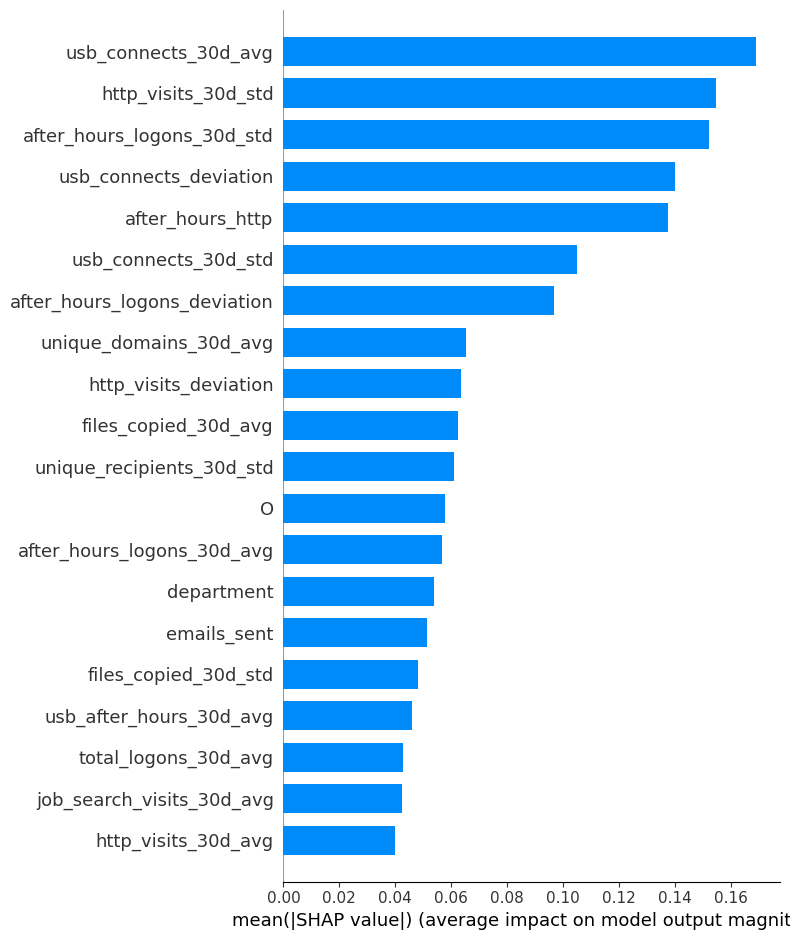


Generating SHAP Beeswarm Plot...


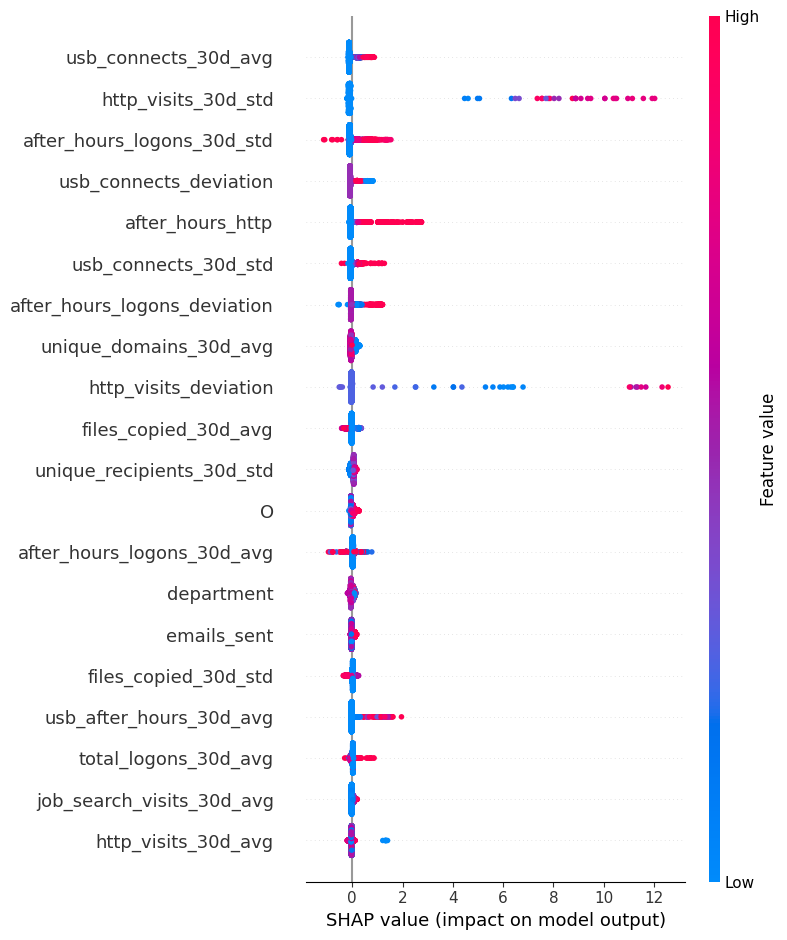


Correct Insider Detections:
258


,record_id,probability,top_feature_1,top_feature_2,top_feature_3,top_feature_4,top_feature_5
0,264395,0.987410,http_visits_30d_std,http_visits_deviation,emails_sent_deviation,after_hours_logons_30d_std,usb_connects_30d_avg
1,264586,0.999943,http_visits_deviation,http_visits_30d_std,emails_sent_deviation,usb_connects_30d_avg,after_hours_logons_30d_std
2,265104,0.998542,http_visits_30d_std,http_visits_deviation,usb_connects_30d_std,after_hours_logons_30d_std,files_copied_30d_avg
3,265149,0.999960,http_visits_deviation,http_visits_30d_std,usb_connects_deviation,usb_connects_30d_avg,after_hours_logons_30d_std
4,265271,0.997358,http_visits_30d_std,http_visits_deviation,usb_connects_30d_std,usb_connects_deviation,files_copied_30d_avg



Saved: insider_reports.csv
SHAP ANALYSIS COMPLETE


In [11]:
# ============================================================
# SHAP + EVIDENCE GENERATION BOOTSTRAP
# ============================================================

import shap
import pandas as pd
import numpy as np

print("="*60)
print("SHAP ANALYSIS STARTING")
print("="*60)

# ------------------------------------------------------------
# BUILD EXPLAINER
# ------------------------------------------------------------

explainer = shap.TreeExplainer(cat_e)

# ------------------------------------------------------------
# SAMPLE TEST DATA
# ------------------------------------------------------------

sample_size = min(5000, len(X_test))

X_shap = X_test.sample(
    sample_size,
    random_state=42
)

print(f"SHAP Sample Size: {len(X_shap)}")

# ------------------------------------------------------------
# COMPUTE SHAP VALUES
# ------------------------------------------------------------

shap_values = explainer.shap_values(X_shap)

print("SHAP Values Computed")

# ------------------------------------------------------------
# GLOBAL FEATURE IMPORTANCE
# ------------------------------------------------------------

mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance = pd.DataFrame({

    "feature": X_shap.columns,

    "mean_abs_shap": mean_abs_shap

})

shap_importance = (
    shap_importance
    .sort_values(
        "mean_abs_shap",
        ascending=False
    )
)

print("\nTOP 20 SHAP FEATURES")
display(
    shap_importance.head(20)
)

# ------------------------------------------------------------
# SUMMARY PLOTS
# ------------------------------------------------------------

print("\nGenerating SHAP Bar Plot...")

shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar"
)

print("\nGenerating SHAP Beeswarm Plot...")

shap.summary_plot(
    shap_values,
    X_shap
)

# ------------------------------------------------------------
# MODEL PREDICTIONS
# ------------------------------------------------------------

pred_probs = (
    cat_e.predict_proba(X_test)
)[:,1]

preds = (
    pred_probs > 0.5
).astype(int)

results = X_test.copy()

results["actual"] = y_test.values
results["prediction"] = preds
results["probability"] = pred_probs

# ------------------------------------------------------------
# CORRECTLY DETECTED INSIDERS
# ------------------------------------------------------------

insider_cases = results[

    (results["actual"] == 1)

    &

    (results["prediction"] == 1)

]

print("\nCorrect Insider Detections:")
print(len(insider_cases))

# ------------------------------------------------------------
# GENERATE INVESTIGATION REPORTS
# ------------------------------------------------------------

insider_reports = []

for idx in insider_cases.index[:100]:

    row = X_test.loc[[idx]]

    row_shap = explainer.shap_values(row)

    case_importance = pd.DataFrame({

        "feature": row.columns,

        "shap": row_shap[0]

    })

    case_importance["abs_shap"] = (
        case_importance["shap"].abs()
    )

    case_importance = (
        case_importance
        .sort_values(
            "abs_shap",
            ascending=False
        )
    )

    top5 = (
        case_importance
        .head(5)
    )

    report = {

        "record_id": idx,

        "probability":
            float(
                pred_probs[
                    X_test.index.get_loc(idx)
                ]
            ),

        "top_feature_1":
            top5.iloc[0]["feature"],

        "top_feature_2":
            top5.iloc[1]["feature"],

        "top_feature_3":
            top5.iloc[2]["feature"],

        "top_feature_4":
            top5.iloc[3]["feature"],

        "top_feature_5":
            top5.iloc[4]["feature"]

    }

    insider_reports.append(
        report
    )

# ------------------------------------------------------------
# SAVE REPORTS
# ------------------------------------------------------------

insider_reports_df = pd.DataFrame(
    insider_reports
)

display(
    insider_reports_df.head()
)

insider_reports_df.to_csv(
    "insider_reports.csv",
    index=False
)

print("\nSaved: insider_reports.csv")

print("="*60)
print("SHAP ANALYSIS COMPLETE")
print("="*60)

In [12]:
!pip install -q google-genai
from kaggle_secrets import UserSecretsClient
from google import genai

user_secrets = UserSecretsClient()

GEMINI_API_KEY = user_secrets.get_secret("GEMINI_API_KEY")

client = genai.Client(api_key=GEMINI_API_KEY)

In [13]:
# ============================================================
# RAG INVESTIGATION ASSISTANT BOOTSTRAP
# ============================================================

!pip -q install sentence-transformers faiss-cpu shap

import shap
import faiss
import numpy as np
import pandas as pd

from sentence_transformers import SentenceTransformer

print("="*60)
print("BUILDING RAG INVESTIGATION ASSISTANT")
print("="*60)

# ------------------------------------------------------------
# SHAP EXPLAINER
# ------------------------------------------------------------

explainer = shap.TreeExplainer(cat_e)

# ------------------------------------------------------------
# PREDICTIONS
# ------------------------------------------------------------

pred_probs = cat_e.predict_proba(X_test)[:,1]

preds = (
    pred_probs > 0.5
).astype(int)

# ------------------------------------------------------------
# BUILD CASE REPORTS
# ------------------------------------------------------------

case_reports = []

insider_idx = np.where(preds == 1)[0]

print(f"Flagged Cases: {len(insider_idx)}")

for idx in insider_idx:

    row = X_test.iloc[[idx]]

    shap_values = explainer.shap_values(row)[0]

    shap_df = pd.DataFrame({
        "feature": row.columns,
        "shap": shap_values,
        "value": row.iloc[0].values
    })

    shap_df["abs"] = shap_df["shap"].abs()
    shap_df = shap_df.sort_values("abs", ascending=False)

    top_features = shap_df.head(5)

    evidence = []

    for _, r in top_features.iterrows():

        evidence.append(
            f"- {r.feature}: {r.value:.3f} (SHAP={r.shap:.3f})"
        )

    risk_flags = []

    r = row.iloc[0]

    if "after_hours_logons" in row.columns:
        if r["after_hours_logons"] > 0:
            risk_flags.append(
                f"{int(r['after_hours_logons'])} after-hours logons"
            )

    if "usb_connects" in row.columns:
        if r["usb_connects"] > 0:
            risk_flags.append(
                f"{int(r['usb_connects'])} USB connections"
            )

    if "files_copied" in row.columns:
        if r["files_copied"] > 0:
            risk_flags.append(
                f"{int(r['files_copied'])} copied files"
            )

    if "emails_sent" in row.columns:
        if r["emails_sent"] > 10:
            risk_flags.append(
                f"High email activity ({int(r['emails_sent'])})"
            )

    if "job_search_visits" in row.columns:
        if r["job_search_visits"] > 0:
            risk_flags.append(
                f"{int(r['job_search_visits'])} job-search visits"
            )

    if len(risk_flags)==0:
        risk_flags.append("Behavioral deviation detected")

    report = f"""
CASE ID : {idx}

Prediction : Insider Threat

Threat Probability : {pred_probs[idx]:.4f}

Observed Risk Indicators

{chr(10).join('- '+x for x in risk_flags)}

Top SHAP Features

{chr(10).join(evidence)}

Behavioral Evidence

This user exhibits behavioural characteristics that differ from the learned normal profile.
The CatBoost classifier identified this activity as anomalous primarily because of the SHAP
features listed above.

Recommended Investigation

• Review user logon history.
• Examine file access and USB activity.
• Inspect recent email communications.
• Validate whether the behaviour aligns with assigned job responsibilities.
"""

    case_reports.append(report)
# ------------------------------------------------------------
# SAVE REPORTS
# ------------------------------------------------------------

reports_df = pd.DataFrame({
    "report": case_reports
})

reports_df.to_csv(
    "rag_case_reports.csv",
    index=False
)

print(
    f"Reports Generated: {len(reports_df)}"
)

# ------------------------------------------------------------
# EMBEDDINGS
# ------------------------------------------------------------

model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

embeddings = model.encode(
    reports_df["report"].tolist(),
    show_progress_bar=True
)

# ------------------------------------------------------------
# FAISS INDEX
# ------------------------------------------------------------

dimension = embeddings.shape[1]

index = faiss.IndexFlatL2(
    dimension
)

index.add(
    embeddings.astype("float32")
)

print(
    f"FAISS Documents: {index.ntotal}"
)

# ------------------------------------------------------------
# QUERY FUNCTION
# ------------------------------------------------------------

def investigate(query, top_k=3):

    query_embedding = model.encode([query])

    D, I = index.search(
        query_embedding.astype("float32"),
        top_k
    )

    retrieved_cases = []

    print("="*70)
    print("INVESTIGATION QUERY")
    print("="*70)
    print(query)

    print("\nRetrieved Similar Cases\n")

    for rank, idx in enumerate(I[0]):

        report = reports_df.iloc[idx]["report"]

        retrieved_cases.append(report)

        print("="*70)
        print(f"CASE {rank+1}")
        print("="*70)

        print(report)

    combined_context = "\n\n".join(retrieved_cases)

    print("\n")
    print("="*70)
    print("LLM GENERATED INVESTIGATION REPORT")
    print("="*70)

    final_report = generate_soc_report(
        query=query,
        retrieved_cases=combined_context
    )

    print(final_report)
def generate_soc_report(query, retrieved_cases):

    prompt = f"""
You are an experienced Security Operations Center (SOC) analyst.

A CatBoost model has identified several potential insider threat cases.

The following investigation reports were retrieved from a FAISS vector database because they are the most semantically relevant to the analyst's query.

===========================
Analyst Query
===========================

{query}

===========================
Retrieved Investigation Cases
===========================

{retrieved_cases}

===========================
Instructions
===========================

Based ONLY on the evidence provided,

Generate a professional insider threat investigation report.

Your report must contain the following sections:

1. Threat Level

2. Executive Summary

3. Behavioural Indicators

4. Important SHAP Features

5. Overall Threat Assessment

6. Recommended Investigation Actions

7. Final Conclusion

Do not invent information that is not present in the retrieved evidence.
Use professional cybersecurity language.
"""

    response = client.models.generate_content(
        model="gemini-2.5-flash",
        contents=prompt
    )

    return response.text
# ------------------------------------------------------------
# TEST QUERY
# ------------------------------------------------------------

investigate(
    "show users with abnormal usb activity"
)

print("="*60)
print("RAG ASSISTANT READY")
print("="*60)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 86.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 106.9 MB/s eta 0:00:0000:010:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is inco

KeyboardInterrupt: 

In [14]:
# ============================================================
# RAG INVESTIGATION ASSISTANT BOOTSTRAP
# ============================================================

!pip -q install sentence-transformers faiss-cpu shap

import shap
import faiss
import numpy as np
import pandas as pd

from sentence_transformers import SentenceTransformer

print("=" * 60)
print("BUILDING RAG INVESTIGATION ASSISTANT")
print("=" * 60)

# ------------------------------------------------------------
# SHAP EXPLAINER
# ------------------------------------------------------------

explainer = shap.TreeExplainer(cat_e)

# ------------------------------------------------------------
# MODEL PREDICTIONS
# ------------------------------------------------------------

pred_probs = cat_e.predict_proba(X_test)[:, 1]
preds = (pred_probs > 0.5).astype(int)

# ------------------------------------------------------------
# BUILD INVESTIGATION REPORTS
# ------------------------------------------------------------

case_reports = []

insider_idx = np.where(preds == 1)[0]

print(f"Flagged Insider Cases : {len(insider_idx)}")

for idx in insider_idx:

    row = X_test.iloc[[idx]]
    current_user = row.iloc[0]

    # --------------------------------------------------------
    # SHAP VALUES
    # --------------------------------------------------------

    shap_values = explainer.shap_values(row)[0]

    shap_df = pd.DataFrame({
        "feature": row.columns,
        "value": current_user.values,
        "shap": shap_values
    })

    shap_df["importance"] = shap_df["shap"].abs()

    shap_df = shap_df.sort_values(
        by="importance",
        ascending=False
    )

    top_features = shap_df.head(5)

    shap_evidence = []

    for _, feature in top_features.iterrows():

        shap_evidence.append(
            f"• {feature.feature}: {feature.value:.3f} "
            f"(SHAP Contribution = {feature.shap:.3f})"
        )

    # --------------------------------------------------------
    # BEHAVIOURAL INDICATORS
    # --------------------------------------------------------

    behavioural_indicators = []

    daily_features = {
        "after_hours_logons": "After-hours logons",
        "weekend_logons": "Weekend logons",
        "usb_connects": "USB connections",
        "usb_after_hours": "After-hours USB usage",
        "files_copied": "Files copied",
        "emails_sent": "Emails sent",
        "job_search_visits": "Job-search website visits",
        "http_visits": "HTTP visits"
    }

    for feature, description in daily_features.items():

        if feature in row.columns:

            value = current_user[feature]

            if value > 0:

                behavioural_indicators.append(
                    f"• {description}: {value:.0f}"
                )

    # --------------------------------------------------------
    # TEMPORAL DEVIATION FEATURES
    # --------------------------------------------------------

    deviation_summary = []

    deviation_features = [
        "total_logons_deviation",
        "usb_connects_deviation",
        "emails_sent_deviation",
        "files_copied_deviation",
        "http_visits_deviation",
        "activity_volume_deviation"
    ]

    for feature in deviation_features:

        if feature in row.columns:

            value = current_user[feature]

            if abs(value) > 1:

                deviation_summary.append(
                    f"• {feature.replace('_',' ').title()} : {value:.2f}"
                )

    # --------------------------------------------------------
    # ENGINEERED RISK FEATURES
    # --------------------------------------------------------

    engineered_risk_summary = []

    engineered_features = [
        "activity_volume",
        "behavior_risk_score",
        "combined_risk",
        "after_hours_risk",
        "external_email_ratio",
        "usb_file_ratio",
        "after_hours_file_ratio",
        "email_usb_interaction"
    ]

    for feature in engineered_features:

        if feature in row.columns:

            engineered_risk_summary.append(
                f"• {feature.replace('_',' ').title()} : "
                f"{current_user[feature]:.3f}"
            )

    # --------------------------------------------------------
    # FALLBACK
    # --------------------------------------------------------

    if len(behavioural_indicators) == 0:

        behavioural_indicators.append(
            "• Behavioural deviation detected."
        )

    if len(deviation_summary) == 0:

        deviation_summary.append(
            "• No significant temporal deviation detected."
        )

    if len(engineered_risk_summary) == 0:

        engineered_risk_summary.append(
            "• Engineered behavioural risk indicators unavailable."
        )

    # --------------------------------------------------------
    # INVESTIGATION REPORT
    # --------------------------------------------------------

    report = f"""
============================================================
CASE ID : {idx}
============================================================

Prediction
----------
Potential Insider Threat

Threat Probability
------------------
{pred_probs[idx]:.4f}

============================================================
Observed Behavioural Indicators
============================================================

{chr(10).join(behavioural_indicators)}

============================================================
Behavioural Deviation Summary
============================================================

{chr(10).join(deviation_summary)}

============================================================
Top SHAP Features
============================================================

{chr(10).join(shap_evidence)}

============================================================
Engineered Behavioural Risk Features
============================================================

{chr(10).join(engineered_risk_summary)}

============================================================
Behavioural Assessment
============================================================

The behavioural profile of this user deviates from the
historical baseline learned by the CatBoost model.

The prediction is primarily influenced by the SHAP features
listed above together with engineered behavioural indicators
capturing temporal deviations, activity volume and overall
risk characteristics.

============================================================
Recommended Investigation
============================================================

• Review authentication history.

• Examine copied files and USB activity.

• Inspect outbound email communications.

• Analyse browsing behaviour and job-search activity.

• Compare current behaviour with historical baseline.

• Validate whether observed actions align with assigned
  organisational responsibilities.
"""

    case_reports.append(report)

# ------------------------------------------------------------
# SAVE REPORTS
# ------------------------------------------------------------

reports_df = pd.DataFrame({
    "report": case_reports
})

reports_df.to_csv(
    "rag_case_reports.csv",
    index=False
)

print(f"Generated Investigation Reports : {len(reports_df)}")

# ------------------------------------------------------------
# SENTENCE TRANSFORMER EMBEDDINGS
# ------------------------------------------------------------

model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

print("=" * 60)
print("GENERATING SEMANTIC EMBEDDINGS")
print("=" * 60)

embeddings = model.encode(
    reports_df["report"].tolist(),
    show_progress_bar=True
)

# ------------------------------------------------------------
# BUILD FAISS VECTOR DATABASE
# ------------------------------------------------------------

dimension = embeddings.shape[1]

index = faiss.IndexFlatL2(dimension)

index.add(
    embeddings.astype("float32")
)

print(f"FAISS Index Created Successfully")
print(f"Indexed Investigation Reports : {index.ntotal}")

# ------------------------------------------------------------
# LLM REPORT GENERATION
# ------------------------------------------------------------

def generate_soc_report(query, retrieved_cases):

    prompt = f"""
You are an experienced Level-2 Security Operations Center (SOC) analyst
investigating potential insider threats within an enterprise network.

The following investigation reports were retrieved from a FAISS semantic
vector database because they are the most relevant to the analyst's query.

Do not include dates unless explicitly present in the retrieved reports.
Summarize recurring evidence rather than repeating identical metrics.

Each retrieved case already contains:

• CatBoost prediction probability
• SHAP explainability
• Behavioural indicators
• Behavioural deviation analysis
• Engineered behavioural risk features

==========================================================
ANALYST QUERY
==========================================================

{query}

==========================================================
RETRIEVED INVESTIGATION CASES
==========================================================

{retrieved_cases}

==========================================================
TASK
==========================================================

Using ONLY the evidence contained within the retrieved
investigation reports,

Generate a professional SOC investigation report.

The report MUST contain the following sections:

1. Threat Level

2. Executive Summary

3. Key Behavioural Indicators

4. SHAP Interpretation

5. Behavioural Deviation Analysis

6. Engineered Risk Feature Analysis

7. Overall Threat Assessment

8. Recommended Investigation Actions

9. Final Conclusion

Important Rules

• Do not invent evidence.

• Every conclusion must be supported using the retrieved
  investigation reports.

• Use professional cybersecurity language suitable for
  SOC analysts.

• Keep the report objective and concise.
"""

    response = client.models.generate_content(
        model="gemini-2.5-flash",
        contents=prompt
    )

    return response.text

# ------------------------------------------------------------
# RAG INVESTIGATION FUNCTION
# ------------------------------------------------------------

def investigate(query, top_k=3):

    print("=" * 70)
    print("SECURITY ANALYST QUERY")
    print("=" * 70)
    print(query)

    query_embedding = model.encode([query])

    distances, indices = index.search(
        query_embedding.astype("float32"),
        top_k
    )

    retrieved_reports = []

    print("\n")
    print("=" * 70)
    print("TOP RETRIEVED INVESTIGATION CASES")
    print("=" * 70)

    for rank, case_index in enumerate(indices[0]):

        report = reports_df.iloc[case_index]["report"]

        retrieved_reports.append(report)

        print(f"\nRetrieved Case {rank+1}")
        print("-" * 70)

        print(f"Similarity Distance : {distances[0][rank]:.4f}\n")

        print(report)

    combined_context = "\n\n".join(retrieved_reports)

    print("\n")
    print("=" * 70)
    print("GENERATING FINAL SOC INVESTIGATION REPORT")
    print("=" * 70)

    final_report = generate_soc_report(
        query=query,
        retrieved_cases=combined_context
    )

    print("\n")
    print("=" * 70)
    print("LLM GENERATED INVESTIGATION REPORT")
    print("=" * 70)

    print(final_report)

    return final_report

# ------------------------------------------------------------
# PAPER DEMONSTRATION
# ------------------------------------------------------------

print("\n")
print("=" * 60)
print("RAG INVESTIGATION DEMONSTRATION")
print("=" * 60)

sample_report = investigate(
    "Identify users exhibiting abnormal USB activity, behavioural deviations and elevated insider threat risk.",
    top_k=3
)

# ------------------------------------------------------------
# SAVE FINAL REPORT
# ------------------------------------------------------------

with open(
    "generated_soc_investigation_report.txt",
    "w",
    encoding="utf-8"
) as f:

    f.write(sample_report)

print("\n")
print("=" * 60)
print("RAG INVESTIGATION ASSISTANT READY")
print("=" * 60)
print("Generated report saved as:")
print("generated_soc_investigation_report.txt")

BUILDING RAG INVESTIGATION ASSISTANT
Flagged Insider Cases : 262


Generated Investigation Reports : 262


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

GENERATING SEMANTIC EMBEDDINGS


Batches:   0%|          | 0/9 [00:00<?, ?it/s]

FAISS Index Created Successfully
Indexed Investigation Reports : 262


RAG INVESTIGATION DEMONSTRATION
SECURITY ANALYST QUERY
Identify users exhibiting abnormal USB activity, behavioural deviations and elevated insider threat risk.


TOP RETRIEVED INVESTIGATION CASES

Retrieved Case 1
----------------------------------------------------------------------
Similarity Distance : 1.2258


CASE ID : 21173

Prediction
----------
Potential Insider Threat

Threat Probability
------------------
0.9996

Observed Behavioural Indicators

• After-hours logons: 1
• USB connections: 3
• After-hours USB usage: 2
• Files copied: 4
• Emails sent: 5
• Job-search website visits: 4
• HTTP visits: 39

Behavioural Deviation Summary

• Emails Sent Deviation : 1.90
• Files Copied Deviation : 1.39
• Http Visits Deviation : 2.74
• Activity Volume Deviation : 12.67

Top SHAP Features

• http_visits_deviation: 2.741 (SHAP Contribution = 10.571)
• http_visits_30d_std: 3.016 (SHAP Contribution = 7.604)
• emails_sent

In [15]:
investigate(
    "show users with abnormal usb activity"
)

SECURITY ANALYST QUERY
show users with abnormal usb activity


TOP RETRIEVED INVESTIGATION CASES

Retrieved Case 1
----------------------------------------------------------------------
Similarity Distance : 1.7314


CASE ID : 21173

Prediction
----------
Potential Insider Threat

Threat Probability
------------------
0.9996

Observed Behavioural Indicators

• After-hours logons: 1
• USB connections: 3
• After-hours USB usage: 2
• Files copied: 4
• Emails sent: 5
• Job-search website visits: 4
• HTTP visits: 39

Behavioural Deviation Summary

• Emails Sent Deviation : 1.90
• Files Copied Deviation : 1.39
• Http Visits Deviation : 2.74
• Activity Volume Deviation : 12.67

Top SHAP Features

• http_visits_deviation: 2.741 (SHAP Contribution = 10.571)
• http_visits_30d_std: 3.016 (SHAP Contribution = 7.604)
• emails_sent_deviation: 1.900 (SHAP Contribution = 0.605)
• usb_after_hours_30d_avg: 0.633 (SHAP Contribution = 0.471)
• usb_connects_30d_avg: 1.867 (SHAP Contribution = 0.431)

Engin

'## SOC Investigation Report: Abnormal USB Activity\n\n**Analyst Query:** show users with abnormal usb activity\n\n**Investigation Scope:** Analysis of retrieved investigation cases (21173, 21391, 21692) related to potential insider threats.\n\n---\n\n### 1. Threat Level\n\n**HIGH.** All retrieved cases consistently indicate a "Potential Insider Threat" with very high threat probabilities ranging from 0.9996 to 0.9999, as predicted by the CatBoost model.\n\n### 2. Executive Summary\n\nMultiple users have been flagged for potential insider threat activity, primarily driven by abnormal USB usage, file exfiltration indicators, and atypical web browsing patterns. The CatBoost model, supported by SHAP explainability, identifies significant deviations from established behavioural baselines. Key indicators include elevated USB connections, files copied, and, in one instance, after-hours USB activity. The high threat probabilities necessitate immediate and detailed investigation into these use

In [ ]:
# ============================================================
# GLOBAL SHAP SUMMARY PLOT
# ============================================================

import shap
import matplotlib.pyplot as plt

explainer = shap.TreeExplainer(cat_e)

# Sample for faster visualization
X_shap = X_test.sample(
    n=min(5000, len(X_test)),
    random_state=42
)

shap_values = explainer.shap_values(X_shap)

plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_values,
    X_shap,
    max_display=20,
    show=False
)

plt.title(
    "Global SHAP Summary of Behavioral Features",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# GLOBAL SHAP FEATURE IMPORTANCE
# ============================================================

plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.title(
    "Global SHAP Feature Importance",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# LOCAL SHAP EXPLANATION - TRUE POSITIVE INSIDER
# ============================================================

import numpy as np

pred_probs = cat_e.predict_proba(X_test)[:, 1]
preds = (pred_probs > 0.5).astype(int)

y_test_array = np.asarray(y_test)

true_positive_idx = np.where(
    (preds == 1) &
    (y_test_array == 1)
)[0]

# Select highest-confidence correctly detected insider
selected_idx = true_positive_idx[
    np.argmax(pred_probs[true_positive_idx])
]

selected_row = X_test.iloc[[selected_idx]]

print("Selected Test Index :", selected_idx)
print("Actual Class        :", y_test_array[selected_idx])
print("Predicted Class     :", preds[selected_idx])
print(
    "Threat Probability  :",
    round(pred_probs[selected_idx], 6)
)

local_shap = explainer(selected_row)

shap.plots.waterfall(
    local_shap[0],
    max_display=15
)

In [ ]:
# ============================================================
# SHAP DECISION PLOT FOR FLAGGED INSIDERS
# ============================================================

insider_indices = np.where(preds == 1)[0][:20]

X_insiders = X_test.iloc[insider_indices]

insider_shap_values = explainer.shap_values(
    X_insiders
)

shap.decision_plot(
    explainer.expected_value,
    insider_shap_values,
    X_insiders.columns,
    feature_display_range=slice(-15, None)
)

plt.title(
    "SHAP Decision Paths for Flagged Insider Cases"
)

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    accuracy_score,
    f1_score
)

thresholds = [
    0.10,0.20,0.30,0.40,
    0.45,0.50,0.55,0.60,
    0.70,0.80,0.90
]

rows = []

for th in thresholds:

    preds = (pred_probs >= th).astype(int)

    rows.append({

        "Threshold": th,
        "Accuracy": accuracy_score(y_test,preds),
        "Precision": precision_score(y_test,preds),
        "Recall": recall_score(y_test,preds),
        "F1-Score": f1_score(y_test,preds)

    })

threshold_df = pd.DataFrame(rows)

threshold_df = threshold_df.round(4)

display(threshold_df)

In [ ]:
# ============================================================
# CATBOOST THRESHOLD ANALYSIS
# ============================================================

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(
    0.05,
    1.00,
    0.01
)

threshold_results = []

cat_probs = model_probabilities[
    "CatBoost"
]

for threshold in thresholds:

    threshold_preds = (
        cat_probs > threshold
    ).astype(int)

    threshold_results.append({

        "Threshold": threshold,

        "Precision":
            precision_score(
                y_test,
                threshold_preds,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_test,
                threshold_preds,
                zero_division=0
            ),

        "F1-Score":
            f1_score(
                y_test,
                threshold_preds,
                zero_division=0
            )
    })

threshold_df = pd.DataFrame(
    threshold_results
)

plt.figure(
    figsize=(10, 7)
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-Score"],
    label="F1-Score"
)

plt.axvline(
    x=0.5,
    linestyle="--",
    label="Selected Threshold = 0.5"
)

plt.xlabel(
    "Decision Threshold"
)

plt.ylabel(
    "Score"
)

plt.title(
    "Effect of Decision Threshold on CatBoost Performance"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# ROC values
fpr, tpr, thresholds = roc_curve(y_test, pred_probs)
auc = roc_auc_score(y_test, pred_probs)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    color='darkorange',
    linewidth=2,
    label=f'ROC Curve (AUC = {auc:.4f})'
)

plt.plot(
    [0,1],
    [0,1],
    linestyle='--',
    color='navy'
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("ROC-AUC =", auc)

In [ ]:
best = threshold_df.loc[
    threshold_df["F1-Score"].idxmax()
]

print(best)

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

precision, recall, _ = precision_recall_curve(
    y_test,
    pred_probs
)

ap = average_precision_score(
    y_test,
    pred_probs
)

plt.figure(figsize=(7,6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=f'AP = {ap:.4f}'
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()